# 25 Terjemahan

Menerjemahkan bahasa Indonesia ke Inggris. Contoh: korpus paralel ALT.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Menerjemahkan Indonesia ke Inggris |
| **Unit prediksi** | Satu kalimat sumber mendapat satu kalimat target |
| **Metrik** | BLEU dan chrF |
| **Masalah terbesar** | Data latih 5.000 pasangan terlalu sedikit untuk melatih dari nol, jadi kualitas sangat bergantung pada model pretrained. |
| **Data contoh** | ALT: 5.000 latih, 500 valid, 1.018 test, kalimat berita |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** data berupa pasangan teks dua bahasa, atau butuh terjemahan untuk memakai model dan kamus berbahasa
Inggris. Metriknya biasanya BLEU atau chrF.

**Yang perlu diganti kalau datanya beda:**
- `load_split` dan kolom bahasa.
- `MODEL_NAME`: `marian_id_en` atau `marian_en_id`.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya kamus kata dari data latih, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
MODEL_NAME = "marian_id_en"
SOURCE_LANG, TARGET_LANG = "id", "en"

SETTINGS = {
    "cepat": {"finetune_rows": 1000, "epochs": 1, "n_test": 500},
    "penuh": {"finetune_rows": 5000, "epochs": 3, "n_test": 1019},
}[MODE]

seed_everything(SEED)
install_offline("sacrebleu")
print(SETTINGS)

{'finetune_rows': 5000, 'epochs': 3, 'n_test': 1019}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Seq2seq.** `generate_texts` menghasilkan teks dari model pretrained. `finetune_seq2seq` melatih model
itu pada data lu sendiri. Bobot akhir tidak disimpan, supaya folder hasil tetap kecil.

In [6]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer as SeqTokenizer  # noqa: E402


def load_seq2seq(name: str):
    tokenizer = SeqTokenizer.from_pretrained(MODEL_DIR / name)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR / name).to(DEVICE)
    return tokenizer, model


@torch.inference_mode()
def generate_texts(
    model, tokenizer, texts, max_input=256, max_new=64, beams=4, batch_size=32, prefix=""
):
    """Hasilkan teks, urut dari yang terpanjang supaya padding lebih hemat."""
    model.eval()
    order = np.argsort([-len(t) for t in texts])
    outputs = [""] * len(texts)
    for start in range(0, len(texts), batch_size):
        picks = order[start : start + batch_size]
        tokens = tokenizer(
            [prefix + texts[i] for i in picks],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_input,
        ).to(DEVICE)
        generated = model.generate(
            **tokens, max_new_tokens=max_new, num_beams=beams, no_repeat_ngram_size=3
        )
        decoded = tokenizer.batch_decode(generated, skip_special_tokens=True)
        for i, text in zip(picks, decoded):
            outputs[i] = text.strip()
    return outputs


def finetune_seq2seq(
    model,
    tokenizer,
    sources,
    targets,
    epochs,
    seed,
    lr=3e-5,
    batch_size=16,
    max_input=256,
    max_target=96,
    prefix="",
):
    """Latih model seq2seq dengan loss bawaan."""
    seed_everything(seed)
    source_tokens = tokenizer(
        [prefix + s for s in sources],
        truncation=True,
        max_length=max_input,
        padding="max_length",
        return_tensors="pt",
    )
    target_ids = tokenizer(
        text_target=list(targets),
        truncation=True,
        max_length=max_target,
        padding="max_length",
        return_tensors="pt",
    )["input_ids"]
    target_ids[target_ids == tokenizer.pad_token_id] = -100
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    generator = np.random.default_rng(seed)
    model.train()
    for _ in range(epochs):
        order = generator.permutation(len(sources))
        for start in range(0, len(order), batch_size):
            pick = torch.as_tensor(order[start : start + batch_size])
            optimizer.zero_grad(set_to_none=True)
            loss = model(
                input_ids=source_tokens["input_ids"][pick].to(DEVICE),
                attention_mask=source_tokens["attention_mask"][pick].to(DEVICE),
                labels=target_ids[pick].to(DEVICE),
            ).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    return model

## 4. EDA

Muat pasangan kalimat. Kolom `translation` berisi kamus per bahasa.

In [7]:
import sacrebleu  # noqa: E402


def load_split(split: str, n_rows: int) -> pd.DataFrame:
    frame = pd.read_parquet(EXTRA_DATA_DIR / "alt" / f"{split}.parquet")
    output = pd.DataFrame(
        {
            "source": frame["translation"].map(lambda d: d[SOURCE_LANG]),
            "target": frame["translation"].map(lambda d: d[TARGET_LANG]),
        }
    )
    output = output[(output["source"].str.len() > 0) & (output["target"].str.len() > 0)]
    return output.head(n_rows).reset_index(drop=True)


train = load_split("train", N_ROWS)
valid = load_split("validation", 500)
test = load_split("test", SETTINGS["n_test"])
print(f"latih={len(train)} | valid={len(valid)} | test={len(test)}")
print("sumber:", train["source"][0][:100])
print("target:", train["target"][0][:100])
pd.DataFrame({"sumber": text_profile(train["source"]), "target": text_profile(train["target"])})

latih=5000 | valid=500 | test=1018
sumber: Italia berhasil mengalahkan Portugal 31-5 di grup C dalam Piala Dunia Rugby 2007 di Parc des Princes
target: Italy have defeated Portugal 31-5 in Pool C of the 2007 Rugby World Cup at Parc des Princes, Paris, 


,sumber,target
baris,5000.0,5000.0
kosong,0.0,0.0
duplikat_persis_%,0.0,0.1
kata_median,19.0,21.0
kata_p95,38.0,41.0
kata_maks,83.0,85.0
ada_url_%,0.0,0.0
ada_emoji_%,0.0,0.0


Rasio panjang sumber dan target. Pasangan yang rasionya ekstrem biasanya salah sejajar.

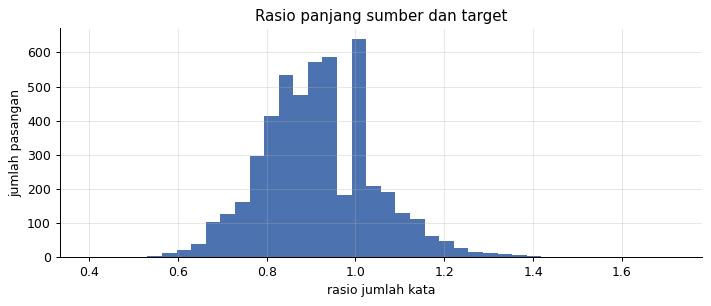

rasio di luar 0,4-2,5: 0.0%


In [8]:
ratio = train["source"].str.split().str.len() / train["target"].str.split().str.len().clip(lower=1)
fig, ax = plt.subplots()
ratio.clip(upper=3).plot.hist(bins=40, ax=ax, color="#4C72B0")
ax.set(
    title="Rasio panjang sumber dan target", xlabel="rasio jumlah kata", ylabel="jumlah pasangan"
)
plt.tight_layout()
plt.show()
print(f"rasio di luar 0,4-2,5: {((ratio < 0.4) | (ratio > 2.5)).mean():.1%}")

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Tidak ada pasangan dengan rasio panjang ekstrem | Filter tidak membuang apa pun, tapi tetap disiapkan untuk data lain |
| Huruf besar dan tanda baca memengaruhi skor | Teks tidak diubah |
| Kalimat median 19 kata | Batas 128 token cukup |

## 5. Preprocessing

Huruf besar dan tanda baca dipertahankan, karena memengaruhi skor. Pasangan yang panjangnya sangat tidak wajar
dibuang hanya dari data latih, sementara data test tetap utuh.

In [9]:
train = train[(ratio >= 0.4) & (ratio <= 2.5)].reset_index(drop=True)
print(f"latih setelah dibersihkan: {len(train)}")

latih setelah dibersihkan: 5000


## 6. Validasi

Memakai pembagian resmi. Valid menentukan apakah fine-tune diterima, dan test hanya untuk laporan. Metrik: BLEU, yang
peka pada urutan kata, dan chrF, yang lebih adil untuk bentuk kata.

In [10]:
def translation_scores(hypotheses: list[str], references: list[str]) -> dict[str, float]:
    return {
        "bleu": round(sacrebleu.corpus_bleu(hypotheses, [references]).score, 2),
        "chrf": round(sacrebleu.corpus_chrf(hypotheses, [references]).score, 2),
    }


assert (
    translation_scores(["the cat sat on the mat today"], ["the cat sat on the mat today"])["bleu"]
    > 99
)
results: list[dict] = []


def record(name: str, pred_valid: list[str], pred_test: list[str]) -> None:
    valid_scores, test_scores = (
        translation_scores(pred_valid, valid["target"].tolist()),
        translation_scores(pred_test, test["target"].tolist()),
    )
    results.append(
        {
            "metode": name,
            "bleu_valid": valid_scores["bleu"],
            "bleu_test": test_scores["bleu"],
            "chrf_test": test_scores["chrf"],
        }
    )
    print(results[-1])

## 7. Baseline

Salin teks sumber, lalu kamus kata dari kemunculan bersama di data latih. Tidak butuh model dari luar.

In [11]:
from collections import Counter, defaultdict  # noqa: E402

record("salin_sumber", valid["source"].tolist(), test["source"].tolist())

co_counts: dict[str, Counter] = defaultdict(Counter)
target_counts: Counter = Counter()
for source, target in zip(train["source"], train["target"]):
    target_words = set(target.lower().split())
    target_counts.update(target_words)
    for word in set(source.lower().split()):
        co_counts[word].update(target_words)
lexicon = {w: max(c, key=lambda t: c[t] / (target_counts[t] + 5)) for w, c in co_counts.items()}


def lexicon_translate(text: str) -> str:
    return " ".join(lexicon.get(word.lower(), word) for word in text.split())


record(
    "kamus_kata",
    valid["source"].map(lexicon_translate).tolist(),
    test["source"].map(lexicon_translate).tolist(),
)

{'metode': 'salin_sumber', 'bleu_valid': 4.57, 'bleu_test': 5.18, 'chrf_test': 25.95}


{'metode': 'kamus_kata', 'bleu_valid': 5.13, 'bleu_test': 5.72, 'chrf_test': 38.8}


## 8. Model Utama

MarianMT pretrained. Lalu fine-tune dari data latih, dan hasilnya hanya dipakai kalau skor valid naik.

In [12]:
valid_final, test_final = (
    valid["source"].map(lexicon_translate).tolist(),
    test["source"].map(lexicon_translate).tolist(),
)
if USE_PRETRAINED:
    tokenizer, model = load_seq2seq(MODEL_NAME)
    with stage("marian_pretrained"):
        valid_base = generate_texts(
            model, tokenizer, valid["source"].tolist(), max_input=128, max_new=128
        )
        test_base = generate_texts(
            model, tokenizer, test["source"].tolist(), max_input=128, max_new=128
        )
    record("marian_pretrained", valid_base, test_base)
    with stage("marian_finetune"):
        subset = train.head(SETTINGS["finetune_rows"])
        model = finetune_seq2seq(
            model,
            tokenizer,
            subset["source"].tolist(),
            subset["target"].tolist(),
            SETTINGS["epochs"],
            SEED,
            batch_size=32,
            max_input=128,
            max_target=128,
        )
        valid_tuned = generate_texts(
            model, tokenizer, valid["source"].tolist(), max_input=128, max_new=128
        )
        test_tuned = generate_texts(
            model, tokenizer, test["source"].tolist(), max_input=128, max_new=128
        )
    record("marian_finetune", valid_tuned, test_tuned)
    del model
    torch.cuda.empty_cache()
    tuned_better = (
        translation_scores(valid_tuned, valid["target"].tolist())["bleu"]
        > translation_scores(valid_base, valid["target"].tolist())["bleu"]
    )
    valid_final, test_final = (valid_tuned, test_tuned) if tuned_better else (valid_base, test_base)
    print("dipilih dari valid:", "fine-tune" if tuned_better else "pretrained")

[waktu] marian_pretrained: 34 detik


{'metode': 'marian_pretrained', 'bleu_valid': 37.72, 'bleu_test': 38.44, 'chrf_test': 64.43}


[waktu] marian_finetune: 334 detik


{'metode': 'marian_finetune', 'bleu_valid': 37.88, 'bleu_test': 39.53, 'chrf_test': 65.02}


dipilih dari valid: fine-tune


## 9. Post-processing

Rapikan keluaran: kata berulang berurutan dibuang, dan spasi sebelum tanda baca dihapus. Kesalahan generator seperti
ini sering muncul pada kalimat panjang.

In [13]:
def tidy_translation(text: str) -> str:
    text = re.sub(r"\b(\w+)( \1\b)+", r"\1", text)
    return re.sub(r"\s+([,.!?;:])", r"\1", text).strip()


record(
    "final_dirapikan",
    [tidy_translation(t) for t in valid_final],
    [tidy_translation(t) for t in test_final],
)
final_test = [tidy_translation(t) for t in test_final]

{'metode': 'final_dirapikan', 'bleu_valid': 37.88, 'bleu_test': 39.53, 'chrf_test': 65.02}


## 10. Post-analysis

**Tabel perbandingan.**

In [14]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,metode,bleu_valid,bleu_test,chrf_test
0,salin_sumber,4.57,5.18,25.95
1,kamus_kata,5.13,5.72,38.80
2,marian_pretrained,37.72,38.44,64.43
3,marian_finetune,37.88,39.53,65.02
4,final_dirapikan,37.88,39.53,65.02


**Skor menurut panjang kalimat.** Kalimat panjang biasanya lebih lemah.

In [15]:
buckets = pd.cut(
    test["source"].str.split().str.len(),
    [0, 10, 20, 40, 1000],
    labels=["<=10", "11-20", "21-40", ">40"],
)
frame = pd.DataFrame({"panjang": buckets, "pred": final_test, "ref": test["target"]})
frame.groupby("panjang", observed=True).apply(
    lambda g: pd.Series(
        {
            "baris": len(g),
            "bleu": round(sacrebleu.corpus_bleu(g["pred"].tolist(), [g["ref"].tolist()]).score, 1),
        }
    ),
    include_groups=False,
)

,baris,bleu
panjang,,
<=10,82.0,39.8
11-20,493.0,39.3
21-40,409.0,39.6
>40,34.0,39.9


**Contoh hasil.**

In [16]:
pd.DataFrame(
    {
        "sumber": test["source"].str[:70],
        "asli": test["target"].str[:70],
        "hasil": [t[:70] for t in final_test],
    }
).head(5)

,sumber,asli,hasil
0,Telah dikonfirmasi bahwa 8 kuda pacu thoroughbred di pacuan kuda Randw,It has been confirmed that eight thoroughbred race horses at Randwick,It has been confirmed that eight thoroughbred racehorses in the Randwi
1,Randwick telah ditutup dan diperkirakan akan sampai dengan 2 bulan ke,"Randwick has been locked down, and is expected to remain so for up to",Randwick has been closed and is expected to reach by the next two mont
2,Diperkirakan bahwa flu mematikan tersebut akan mempengaruhi sebagian b,It is expected that the virulent flu will affect the majority of the 7,It is estimated that the deadly flu will affect most of the 700 horses
3,Menteri Industri Utama NSW berkata bahwa fasilitas akan dikarantina se,NSW Minister for Primary Industries said the facility would be quarant,The MSW Main Industry Minister said that the facility would be quarant
4,"Kasus ini adalah infeksi pertama pada kuda pacu, disamping menginfeksi","The cases are the first infections of race horses, despite infecting d","The case is the first infection on race horses, besides infecting doze"


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [17]:
pd.DataFrame({"id": test.index, "terjemahan": final_test}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "terjemahan",
    len(train),
    {r["metode"]: {"bleu_test": r["bleu_test"], "chrf_test": r["chrf_test"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=terjemahan mode=penuh n_rows=5000 total_detik=458 gpu=True
{
 "salin_sumber": {
  "bleu_test": 5.18,
  "chrf_test": 25.95
 },
 "kamus_kata": {
  "bleu_test": 5.72,
  "chrf_test": 38.8
 },
 "marian_pretrained": {
  "bleu_test": 38.44,
  "chrf_test": 64.43
 },
 "marian_finetune": {
  "bleu_test": 39.53,
  "chrf_test": 65.02
 },
 "final_dirapikan": {
  "bleu_test": 39.53,
  "chrf_test": 65.02
 }
}


**Poin untuk presentasi**

- Fine-tune hanya sedikit menaikkan BLEU test: 38,44 ke 39,53, setelah 334 detik.
- Kamus kata buatan sendiri hanya 5,72, jadi tanpa pretrained task ini tidak realistis.
- BLEU sekitar 39 di semua panjang kalimat.
- Merapikan keluaran tidak mengubah skor pada data ini.